# 10 — Report Exhibits

**Tail Risk Adequacy**
High_Magus_of_Risk

---

## Objective

Read the CSV artefacts produced by notebooks 01-09 and assemble report-ready
figures and tables in `data/report_exhibits/`. Designed to be runnable both
before and after the Phase 3 integration:

- Exhibits sourced from the Phase 2 pipeline (engine ranking, stress
  scorecard, cost-of-being-wrong, drawdown episodes, realised-vs-simulated
  MDD) run today.
- Exhibits sourced from Phase 3 (DCC ρ_t, t-copula tail dependence, the
  sensitivity grid, formal-test scorecards) appear once the upstream
  notebooks are extended per `PHASE3_INTEGRATION.md`.

Every load is wrapped in a graceful "file not found" check, so the notebook
prints a note rather than failing when a Phase 3 artefact does not yet exist.


---
## 1  Setup

In [11]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = 'data'
OUT  = 'data/report_exhibits'
FIG  = os.path.join(OUT, 'figures')
os.makedirs(FIG, exist_ok=True)

pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.grid': True,
                     'grid.alpha': 0.3, 'font.size': 11})


def try_read(path, **kwargs):
    full = os.path.join(DATA, path)
    if not os.path.exists(full) or os.path.getsize(full) == 0:
        print(f'  [skip] {path} - file not found or empty')
        return None
    try:
        return pd.read_csv(full, **kwargs)
    except Exception as e:
        print(f'  [skip] {path} - read error: {e}')
        return None


tables = {}   # all loaded tables -> exhibits.xlsx at the end
figures = {}  # all produced figures
print(f'Outputs will be written to ./{OUT}/')

Outputs will be written to ./data/report_exhibits/


---
## 2  Exhibit A — Engine ranking (the verdict at a glance)

Exhibit A: synthesis_ranking.csv


,Portfolio,Engine,Exc rate,p_uc,p_cc,Windows_passed,Windows_tested,Rank
0,Port_FO,GARCH-FHS,0.0123,0.0681,0.0479,4,4,1
1,Port_FO,t_nu4,0.0148,0.0003,0.0000,2,4,2
2,Port_FO,t_nu6,0.0173,0.0000,0.0000,2,4,3
3,Port_FO,t_nu10,0.0184,0.0000,0.0000,2,4,4
4,Port_FO,Gaussian,0.0208,0.0000,0.0000,1,4,5


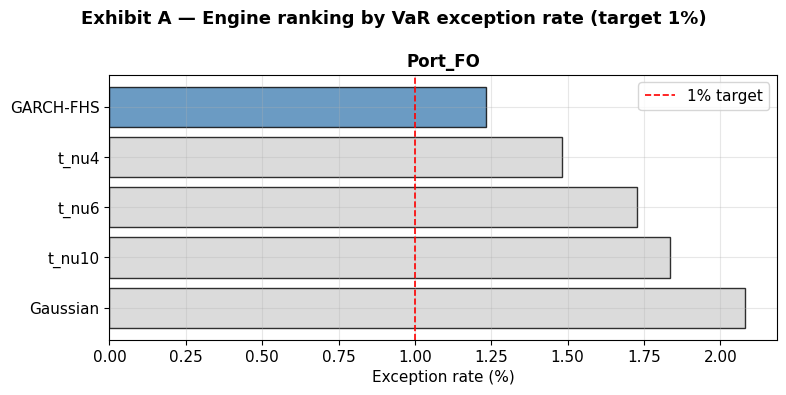

In [12]:
print('Exhibit A: synthesis_ranking.csv')
rank = try_read('scorecards/synthesis_ranking.csv')
if rank is not None:
    rank = rank.sort_values(['Portfolio', 'Rank']).reset_index(drop=True)
    tables['A_engine_ranking'] = rank
    display(rank)

    fig, axes = plt.subplots(1, 1, figsize=(8, 4)); axes = np.atleast_1d(axes)
    for ax, port in zip(axes, rank['Portfolio'].unique()):
        sub = rank[rank['Portfolio'] == port].sort_values('Rank')
        colors = ['steelblue' if e == 'GARCH-FHS' else 'lightgray'
                  for e in sub['Engine']]
        ax.barh(sub['Engine'], sub['Exc rate'] * 100, color=colors,
                edgecolor='k', alpha=0.8)
        ax.axvline(1.0, color='red', ls='--', lw=1.2, label='1% target')
        ax.set_title(port, fontsize=12, fontweight='bold')
        ax.set_xlabel('Exception rate (%)')
        ax.invert_yaxis()
        ax.legend()
    plt.suptitle('Exhibit A — Engine ranking by VaR exception rate (target 1%)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG, 'exhibit_A_engine_ranking.png'), dpi=120,
                bbox_inches='tight')
    plt.show()
    figures['A_engine_ranking'] = 'exhibit_A_engine_ranking.png'

---
## 3  Exhibit B — Stress-window scorecard

In [13]:
print('Exhibit B: stress.csv + stress_phase2.csv')
s1 = try_read('scorecards/stress.csv')
s2 = try_read('scorecards/stress_phase2.csv')
if s1 is not None:
    keep_cols = ['Window', 'Portfolio', 'Engine', 'N exc', 'Kupiec p']
    if 'CC reject' in s1.columns:
        keep_cols.append('CC reject')
    s1c = s1[keep_cols].copy()
    parts = [s1c]
    if s2 is not None:
        ren = {'p_uc': 'Kupiec p'}
        s2c = s2.rename(columns=ren)
        s2c = s2c[['Window', 'Portfolio', 'Engine', 'N exc', 'Kupiec p']]
        parts.append(s2c)
    stress = pd.concat(parts, ignore_index=True)
    stress['pass_5pct'] = stress['Kupiec p'] >= 0.05
    tables['B_stress_scorecard'] = stress

    pivot = stress.pivot_table(index=['Portfolio', 'Engine'],
                               columns='Window',
                               values='pass_5pct', aggfunc='first')
    print('Pass / fail (Kupiec p >= 0.05) by engine x window:')
    display(pivot.astype(bool))
    tables['B_stress_pivot'] = pivot.astype(bool).reset_index()

Exhibit B: stress.csv + stress_phase2.csv
Pass / fail (Kupiec p >= 0.05) by engine x window:


Window               COVID  DotCom_2000_2003    GFC  Rate_Hikes_2022
Portfolio Engine                                                    
Port_FO   GARCH-FHS   True              True   True             True
          Gaussian   False              True  False            False
          t_nu10     False              True  False             True
          t_nu4      False              True  False             True
          t_nu6      False              True  False             True

---
## 4  Exhibit C — Cost of being wrong

Exhibit C: cost_of_being_wrong.csv


,Portfolio,Engine,N days,Breaches,Expected,Excess breaches,Mean breach shortfall,Worst-day shortfall,Mean ES gap,Avg VaR cushion
0,Port_FO,Gaussian,6485,135,65,70,0.0073,0.0571,0.0052,0.0157
1,Port_FO,t_nu10,6485,119,65,54,0.0073,0.0564,0.0041,0.0167
2,Port_FO,t_nu6,6485,112,65,47,0.0072,0.0559,0.0029,0.0173
3,Port_FO,t_nu4,6485,96,65,31,0.0079,0.0554,0.0017,0.0179
4,Port_FO,GARCH-FHS,6485,80,65,15,0.0032,0.0133,-0.0004,0.0159


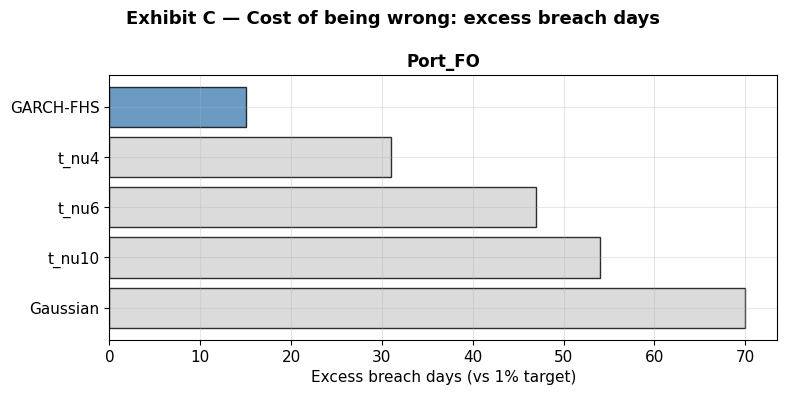

In [14]:
print('Exhibit C: cost_of_being_wrong.csv')
cost = try_read('scorecards/cost_of_being_wrong.csv')
if cost is not None:
    tables['C_cost_of_being_wrong'] = cost
    display(cost.round(5))

    fig, axes = plt.subplots(1, 1, figsize=(8, 4)); axes = np.atleast_1d(axes)
    for ax, port in zip(axes, cost['Portfolio'].unique()):
        sub = cost[cost['Portfolio'] == port].sort_values('Excess breaches')
        colors = ['steelblue' if e == 'GARCH-FHS' else 'lightgray'
                  for e in sub['Engine']]
        ax.barh(sub['Engine'], sub['Excess breaches'], color=colors,
                edgecolor='k', alpha=0.8)
        ax.set_title(port, fontsize=12, fontweight='bold')
        ax.set_xlabel('Excess breach days (vs 1% target)')
        ax.invert_yaxis()
    plt.suptitle('Exhibit C — Cost of being wrong: excess breach days',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG, 'exhibit_C_excess_breaches.png'), dpi=120,
                bbox_inches='tight')
    plt.show()
    figures['C_excess_breaches'] = 'exhibit_C_excess_breaches.png'

---
## 5  Exhibit D — Realised drawdown episodes

In [15]:
print('Exhibit D: episodes_Port_FO.csv')
epfo = try_read('drawdowns/episodes_Port_FO.csv',
                parse_dates=['peak_date', 'trough_date', 'recovery_date'])

def top5(df, port):
    if df is None or df.empty:
        return None
    d = df.sort_values('depth', ascending=False).head(5).copy()
    d.insert(0, 'Portfolio', port)
    return d

topfo = top5(epfo, 'Family-Office')
combined = pd.concat([t for t in [topfo] if t is not None], ignore_index=True)
if combined is not None and not combined.empty:
    tables['D_drawdown_episodes'] = combined
    display(combined.round(4))

Exhibit D: episodes_Port_FO.csv


,Portfolio,peak_date,trough_date,recovery_date,depth,days_to_trough,days_to_recovery,total_underwater_days
0,Family-Office,2007-10-09,2009-03-09,2010-04-23,0.3999,355,639.0000,638
1,Family-Office,2020-02-20,2020-03-23,2020-08-10,0.2331,22,119.0000,118
2,Family-Office,2022-01-04,2022-10-14,2024-02-08,0.2057,196,526.0000,525
3,Family-Office,2000-09-01,2002-10-09,2003-06-05,0.1576,520,679.0000,678
4,Family-Office,1998-07-17,1998-10-08,1999-01-08,0.1384,57,118.0000,117


---
## 6  Exhibit E — Realised vs simulated MDD

Exhibit E: realised_summary.csv + simulated_mdd.csv


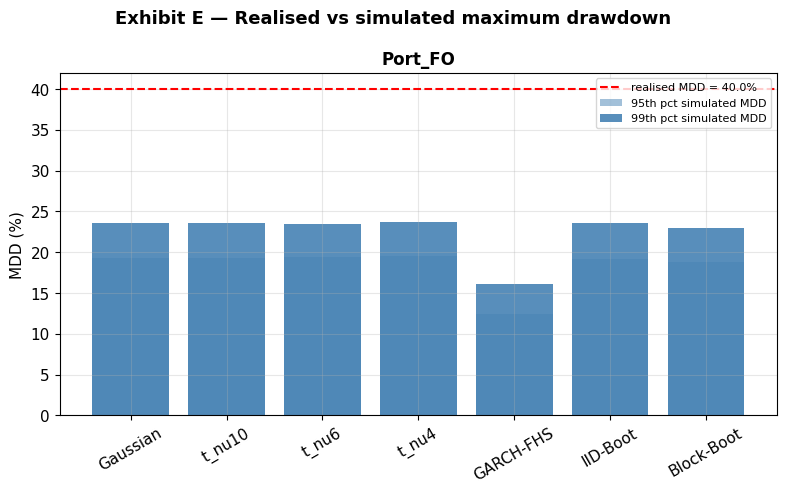

In [16]:
print('Exhibit E: realised_summary.csv + simulated_mdd.csv')
real = try_read('drawdowns/realised_summary.csv')
sim  = try_read('drawdowns/simulated_mdd.csv')
if real is not None and sim is not None:
    tables['E_realised_summary'] = real
    tables['E_simulated_mdd'] = sim

    fig, axes = plt.subplots(1, 1, figsize=(8, 5)); axes = np.atleast_1d(axes)
    for ax, port in zip(axes, sim['Portfolio'].unique()):
        sub = sim[sim['Portfolio'] == port]
        ax.bar(sub['Engine'], sub['MDD 95%-tile'] * 100, color='steelblue',
               alpha=0.5, label='95th pct simulated MDD')
        ax.bar(sub['Engine'], sub['MDD 99%-tile'] * 100, color='steelblue',
               alpha=0.9, label='99th pct simulated MDD')
        r = float(sub['Realised MDD'].iloc[0]) * 100
        ax.axhline(r, color='red', ls='--', lw=1.5,
                   label=f'realised MDD = {r:.1f}%')
        ax.set_title(port, fontsize=12, fontweight='bold')
        ax.set_ylabel('MDD (%)')
        ax.tick_params(axis='x', rotation=30)
        ax.legend(fontsize=8)
    plt.suptitle('Exhibit E — Realised vs simulated maximum drawdown',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG, 'exhibit_E_mdd_realised_vs_simulated.png'),
                dpi=120, bbox_inches='tight')
    plt.show()
    figures['E_mdd_realised_vs_sim'] = 'exhibit_E_mdd_realised_vs_simulated.png'

---
## 7  Exhibit F — DCC correlation through crises (notebook 09 output)

This exhibit appears once notebook 09 has been run.

Exhibit F: dcc/rho_t.csv + dcc/dcc_params.csv


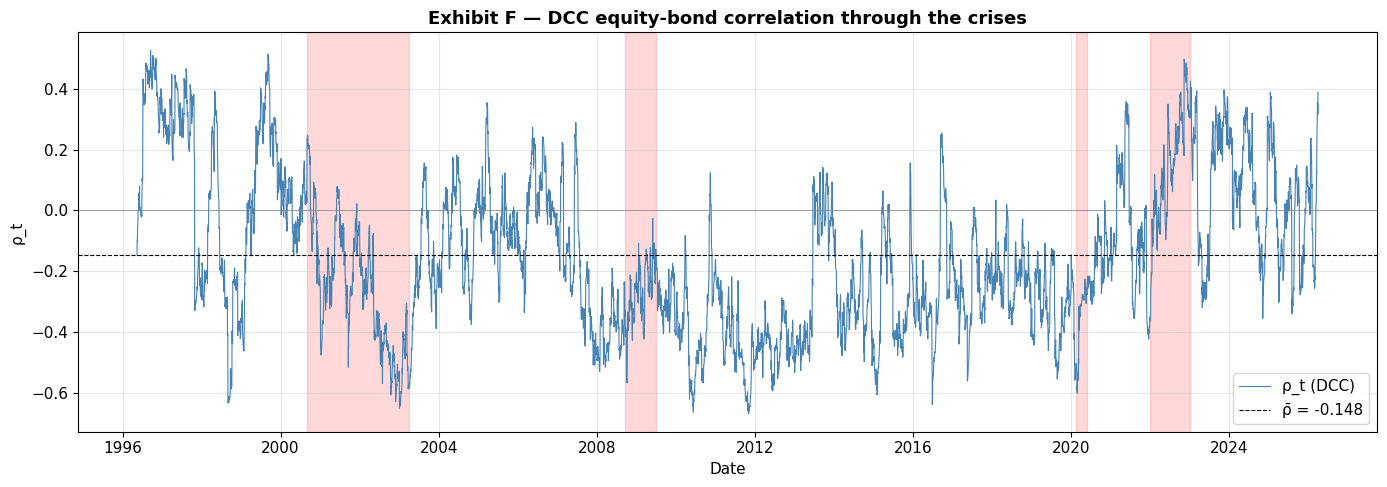


t-copula tail dependence (calm vs peak ρ):


,nu,lambda_calm,lambda_peak
0,4,0.0980,0.2684
1,6,0.0473,0.1843
2,10,0.0118,0.0919
3,30,0.0000,0.0041


In [17]:
print('Exhibit F: dcc/rho_t.csv + dcc/dcc_params.csv')
rho = try_read('dcc/rho_t.csv', index_col=0, parse_dates=True)
params = try_read('dcc/dcc_params.csv')
if rho is not None and params is not None:
    tables['F_dcc_rho_t'] = rho.reset_index()
    tables['F_dcc_params'] = params
    rho_bar = float(params['rho_bar'].iloc[0])

    with open(os.path.join(DATA, 'stress_windows.json')) as f:
        sw = json.load(f)

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(rho.index, rho['rho_t'].values, lw=0.8, color='steelblue',
            label='ρ_t (DCC)')
    ax.axhline(rho_bar, color='black', lw=0.8, ls='--',
               label=f'ρ̄ = {rho_bar:+.3f}')
    ax.axhline(0, color='gray', lw=0.5)
    for name, w in sw.items():
        ax.axvspan(pd.Timestamp(w['start']), pd.Timestamp(w['end']),
                   alpha=0.15, color='red')
    ax.set_title('Exhibit F — DCC equity-bond correlation through the crises',
                 fontsize=13, fontweight='bold')
    ax.set_ylabel('ρ_t')
    ax.set_xlabel('Date')
    ax.legend(loc='lower right')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG, 'exhibit_F_dcc_rho_t.png'),
                dpi=120, bbox_inches='tight')
    plt.show()
    figures['F_dcc_rho_t'] = 'exhibit_F_dcc_rho_t.png'

td = try_read('dcc/tail_dependence.csv')
if td is not None:
    print('\nt-copula tail dependence (calm vs peak ρ):')
    display(td.round(4))
    tables['F_tail_dependence'] = td

---
## 8  Exhibit G — Phase 3 sensitivity grid (when available)

Appears once notebooks 03-08 have been re-run across the 95/97.5/99% x 2y/3y
grid per `PHASE3_INTEGRATION.md`. We look for `data/scorecards/grid_*.csv`.

In [18]:
import glob
grid_files = sorted(glob.glob(os.path.join(DATA, 'scorecards', 'grid_*.csv')))
if not grid_files:
    print('  [skip] no data/scorecards/grid_*.csv yet -- run the Phase 3 grid first')
else:
    grid = pd.concat([pd.read_csv(f) for f in grid_files], ignore_index=True)
    tables['G_sensitivity_grid'] = grid
    print(f'Loaded {len(grid_files)} grid files; {len(grid):,} rows.')
    display(grid.head(20))

  [skip] no data/scorecards/grid_*.csv yet -- run the Phase 3 grid first


---
## 8  Exhibit H — Formal ES backtests (McNeil-Frey + Acerbi-Szekely)

Loads the ES-test scorecards produced by notebooks 04 and 05 and emits a
report-ready table + figure: McNeil-Frey one-sided p-values per engine and
the Acerbi-Szekely Z2 statistic (a negative Z2 means ES under-estimates the
tail). Appears once notebooks 04 and 05 have been run.

Exhibit H: es_overall.csv + es_overall_phase2.csv + es_stress*.csv


,Portfolio,Engine,N obs,N exc,Mean residual,MF p-value,MF CI low,MF CI high,MF reject,Z2,Z2 CI low,Z2 CI high,Z2 reject
0,Port_FO,Gaussian,6485,135,0.0052,0.0000,0.0037,0.0069,True,-1.7911,-2.3336,-1.2799,True
1,Port_FO,t_nu10,6485,119,0.0041,0.0001,0.0025,0.0059,True,-1.2760,-1.7528,-0.8335,True
2,Port_FO,t_nu6,6485,112,0.0029,0.0021,0.0012,0.0047,True,-0.9964,-1.4266,-0.6018,True
3,Port_FO,t_nu4,6485,96,0.0017,0.0568,-0.0002,0.0038,False,-0.6068,-0.9786,-0.2687,True
4,Port_FO,GARCH-FHS,6485,80,-0.0004,0.8049,-0.0013,0.0005,False,-0.2368,-0.5299,0.0341,False


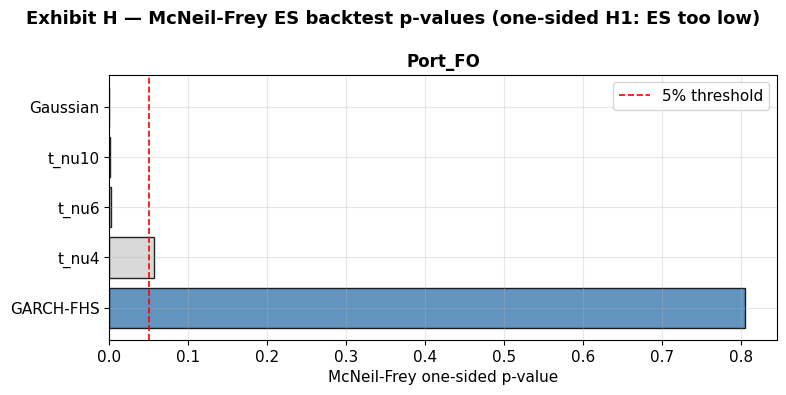


Stress-window ES backtests:


,Window,Portfolio,Engine,N obs,N exc,Mean residual,MF p-value,MF CI low,MF CI high,MF reject,Z2,Z2 CI low,Z2 CI high,Z2 reject
0,DotCom_2000_2003,Port_FO,Gaussian,637,9,0.0002,0.3585,-0.0008,0.0013,False,-0.4289,-1.4448,0.3959,False
1,DotCom_2000_2003,Port_FO,t_nu10,637,7,-0.0014,1.0000,-0.0024,-0.0002,False,-0.0160,-0.8736,0.5987,False
2,DotCom_2000_2003,Port_FO,t_nu6,637,6,-0.0029,1.0000,-0.0039,-0.0016,False,0.1926,-0.5210,0.7470,False
3,DotCom_2000_2003,Port_FO,t_nu4,637,4,-0.0048,1.0000,-0.0060,-0.0031,False,0.5032,-0.0658,0.8872,False
4,GFC,Port_FO,Gaussian,200,33,0.0091,0.0000,0.0056,0.0129,True,-23.7651,-32.7372,-15.7940,True
5,GFC,Port_FO,t_nu10,200,30,0.0077,0.0000,0.0041,0.0118,True,-19.7564,-27.6440,-12.7234,True
6,GFC,Port_FO,t_nu6,200,29,0.0061,0.0025,0.0023,0.0101,True,-17.5821,-24.9046,-11.1634,True
7,GFC,Port_FO,t_nu4,200,26,0.0045,0.0224,0.0005,0.0089,True,-14.5209,-20.8438,-8.9302,True
8,COVID,Port_FO,Gaussian,72,16,0.0133,0.0032,0.0056,0.0224,True,-43.4242,-68.5926,-21.7810,True
9,COVID,Port_FO,t_nu10,72,15,0.0125,0.0045,0.0045,0.0218,True,-37.2482,-59.5906,-18.1157,True


In [19]:
print('Exhibit H: es_overall.csv + es_overall_phase2.csv + es_stress*.csv')
es_p1 = try_read('scorecards/es_overall.csv')
es_p2 = try_read('scorecards/es_overall_phase2.csv')
parts = [df for df in (es_p1, es_p2) if df is not None]
if parts:
    es_overall = pd.concat(parts, ignore_index=True)
    tables['H_es_overall'] = es_overall
    display(es_overall.round(5))

    if {'Portfolio', 'Engine', 'MF p-value', 'Z2'}.issubset(es_overall.columns):
        fig, axes = plt.subplots(1, 1, figsize=(8, 4)); axes = np.atleast_1d(axes)
        for ax, port in zip(axes, es_overall['Portfolio'].unique()):
            sub = es_overall[es_overall['Portfolio'] == port].copy()
            colors = ['steelblue' if e == 'GARCH-FHS' else 'lightgray'
                      for e in sub['Engine']]
            ax.barh(sub['Engine'], sub['MF p-value'].astype(float),
                    color=colors, edgecolor='k', alpha=0.85)
            ax.axvline(0.05, color='red', ls='--', lw=1.2, label='5% threshold')
            ax.set_title(port, fontsize=12, fontweight='bold')
            ax.set_xlabel('McNeil-Frey one-sided p-value')
            ax.invert_yaxis()
            ax.legend()
        plt.suptitle('Exhibit H — McNeil-Frey ES backtest p-values (one-sided H1: ES too low)',
                     fontsize=13, fontweight='bold')
        plt.tight_layout()
        plt.savefig(os.path.join(FIG, 'exhibit_H_mcneil_frey.png'), dpi=120,
                    bbox_inches='tight')
        plt.show()
        figures['H_mcneil_frey'] = 'exhibit_H_mcneil_frey.png'

# stress-window ES
es_stress_p1 = try_read('scorecards/es_stress.csv')
es_stress_p2 = try_read('scorecards/es_stress_phase2.csv')
stress_parts = [df for df in (es_stress_p1, es_stress_p2) if df is not None]
if stress_parts:
    es_stress = pd.concat(stress_parts, ignore_index=True)
    tables['H_es_stress'] = es_stress
    print('\nStress-window ES backtests:')
    display(es_stress.round(5))

---
## 9  Save all exhibits

In [20]:
xlsx_path = os.path.join(OUT, 'exhibits.xlsx')
with pd.ExcelWriter(xlsx_path) as writer:
    for sheet, df in tables.items():
        if df is None or len(df) == 0:
            continue
        df.to_excel(writer, sheet_name=sheet[:31], index=False)

print(f'Wrote {len([t for t in tables.values() if t is not None])} '
      f'tables to {xlsx_path}')
print(f'Wrote {len(figures)} figures to {FIG}/')
for k, v in figures.items():
    print(f'  - {k}: {v}')

missing = [k for k in ['A_engine_ranking', 'B_stress_scorecard',
                       'C_cost_of_being_wrong', 'D_drawdown_episodes',
                       'E_realised_summary', 'F_dcc_rho_t',
                       'G_sensitivity_grid', 'H_es_overall']
           if k not in tables]
if missing:
    print(f'\nNot yet available (run upstream notebooks): {missing}')

Wrote 12 tables to data/report_exhibits\exhibits.xlsx
Wrote 5 figures to data/report_exhibits\figures/
  - A_engine_ranking: exhibit_A_engine_ranking.png
  - C_excess_breaches: exhibit_C_excess_breaches.png
  - E_mdd_realised_vs_sim: exhibit_E_mdd_realised_vs_simulated.png
  - F_dcc_rho_t: exhibit_F_dcc_rho_t.png
  - H_mcneil_frey: exhibit_H_mcneil_frey.png

Not yet available (run upstream notebooks): ['G_sensitivity_grid']


---
## 10  Summary

This notebook is the single place to regenerate the study's exhibits.
Run it whenever upstream notebooks have been updated and a fresh set of
figures and tables is needed. The Excel workbook `exhibits.xlsx` contains
every supporting table; the PNG figures sit in `data/report_exhibits/figures/`.

Once notebooks 03-08 are extended for the Phase 3 grid and the formal
tests, this notebook should pick up the new artefacts automatically and
emit the corresponding exhibits without further edits.

---
## Exhibit FO: Responsive FO strategy (NB11)

The responsive GARCH-FHS overlay vs the static policy portfolio, plus the vol-target
sensitivity frontier used to calibrate it.

In [21]:
print('Exhibit FO: fo_strategy_comparison.csv + fo_vol_target_frontier.csv')
cmp_fo = try_read('report_exhibits/fo_strategy_comparison.csv', index_col=0)
fr_fo  = try_read('report_exhibits/fo_vol_target_frontier.csv', index_col=0)
if cmp_fo is not None: display(cmp_fo)
if fr_fo is not None: display(fr_fo)

Exhibit FO: fo_strategy_comparison.csv + fo_vol_target_frontier.csv


,avg weight,ann vol %,VaR99 %,MaxDD %,Sharpe,Sortino,CDaR95 %,%TuW,CAGR %
variant,,,,,,,,,
Static FO,1.0000,10.8700,1.9590,34.8300,0.4930,0.6920,20.9200,87.1000,7.2800
Responsive (vol-target 8%),0.8380,6.9100,1.1860,15.9800,0.5730,0.8000,12.1200,88.5000,6.1600


,avg weight,ann vol %,VaR99 %,MaxDD %,CDaR95 %,Sharpe,Sortino,CAGR %
vol target %,,,,,,,,
6.0000,0.6850,5.4900,0.9120,11.8300,8.7200,0.5380,0.7470,5.2000
7.0000,0.7740,6.2700,1.0600,13.9400,10.4900,0.5600,0.7800,5.7300
8.0000,0.8380,6.9100,1.1860,15.9800,12.1200,0.5730,0.8000,6.1600
9.0000,0.8810,7.4200,1.2570,18.2800,13.5500,0.5830,0.8160,6.5100
10.0000,0.9090,7.8100,1.3320,19.7500,14.6000,0.5770,0.8080,6.6700
12.0000,0.9450,8.4000,1.4460,21.4200,15.4500,0.5760,0.8080,6.9800
15.0000,0.9680,8.9600,1.5660,24.1900,16.7200,0.5760,0.8110,7.2700
